# Passaggio 3 esteso: notizie di Alpaca per le 10 coppie

**Obiettivo.** Ripetere per le 10 coppie quanto fatto su MA-V in [notizie_mav.ipynb](notizie_mav.ipynb): controllare la qualità delle notizie di Alpaca (fonte Benzinga) e misurare **quanti segnali hanno una notizia prima**, per i **624 segnali** del train di [segnali_coppie.ipynb](segnali_coppie.ipynb). Solo periodo di addestramento (fino al 16 settembre 2026): il test non si usa.

**Prima di aprirlo** servono due file. Le motivazioni di orari, filtri e finestre sono in [notizie_mav.ipynb](notizie_mav.ipynb) e qui non si ripetono.
1. Le notizie dei 20 titoli (serve il file `.env` con le chiavi di Alpaca, vedi `notizie_mav.ipynb`). Dalla cartella del progetto:
   ```bash
   uv run python -m src.news --pair ALL10
   ```
   Crea `data/raw/news/alpaca/ALL10_.../` (risposte grezze) e `data/processed/news_ALL10_train.parquet`.
2. I segnali: eseguire `segnali_coppie.ipynb` (crea `data/processed/signals_10pairs_train.csv`).

| Parte | Cosa fa | Perché |
|---|---|---|
| 1 | Parametri | |
| 2 | Caricamento e controllo di coerenza con MA-V | le notizie di MA e V devono essere le stesse di prima |
| 3 | Qualità delle notizie per titolo | quante, quanto mirate |
| 4 | Controllo degli orari | l'agente non deve vedere il futuro |
| 5 | Copertura per coppia, confrontata con orari casuali | quanti segnali hanno una notizia prima |
| 6 | Le notizie c'entrano col risultato del trade? | l'ipotesi del progetto, in forma descrittiva |
| 7 | Tabella notizie-segnali | input del Passaggio 5 |
| 8 | Esempi da leggere a mano | |
| 9 | Conclusioni e cose aperte | |

## 1. Parametri

In [1]:
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
from pathlib import Path

from signals import list_pairs, load_pair, TRAIN_END, OPEN_SKIP, CLOSE_SKIP, N_MINUTES

NEWS_PATH = Path("../data/processed/news_ALL10_train.parquet")             # creata da `python -m src.news --pair ALL10`
NEWS_MAV_PATH = Path("../data/processed/news_MA-V_train.parquet")          # notizie di sola MA-V (notizie_mav.ipynb), per il controllo di coerenza
SIGNALS_PATH = Path("../data/processed/signals_10pairs_train.csv")         # creata da segnali_coppie.ipynb
OUT_LINK = Path("../data/processed/news_for_signals_10pairs_train.csv")    # input del Passaggio 5

WINDOWS_H = [2, 6, 24]             # [SCELTA] finestre di ricerca prima del segnale, in ore (le stesse di notizie_mav.ipynb)
MAX_SYMBOLS_FOCUSED = 3            # [SCELTA] una notizia è "mirata" se cita al massimo 3 ticker
N_PLACEBO_PER_SIGNAL = 50          # per ogni segnale, giorni di borsa casuali (alla stessa ora del giorno) per il confronto di copertura
SEED = 0

## 2. Caricamento e controllo di coerenza

In [2]:
for f in (NEWS_PATH, SIGNALS_PATH):
    if not f.exists():
        raise FileNotFoundError(f"{f.name} non trovato: segui le istruzioni all'inizio del notebook")

read = lambda path: duckdb.sql(f"SELECT * FROM '{path.as_posix()}'").df()
news = read(NEWS_PATH).sort_values("ts").reset_index(drop=True)
signals = pd.read_csv(SIGNALS_PATH, parse_dates=["t_signal", "t_entry", "t_exit"])
pairs = list_pairs()

train_end = pd.Timestamp(TRAIN_END) + pd.Timedelta(days=1)
assert news.ts.max() < train_end and signals.t_exit.max() < train_end, "ci sono dati dopo la fine del train: il test non si usa"
news["focused"] = news.n_symbols <= MAX_SYMBOLS_FOCUSED
tick_cols = {s: f"mentions_{s}" for s in sorted(set(pairs.sym_A) | set(pairs.sym_B))}
assert all(c in news.columns for c in tick_cols.values())

print(f"notizie: {len(news):,}, dal {news.ts.min()} al {news.ts.max()}   |   segnali: {len(signals)}, {signals.pair.nunique()} coppie")

# controllo: le notizie che citano MA o V sono le stesse scaricate per notizie_mav.ipynb
if NEWS_MAV_PATH.exists():
    mav = read(NEWS_MAV_PATH)
    ids_all = set(news.loc[news.mentions_MA | news.mentions_V, "id"])
    print(f"MA-V: {len(ids_all)} notizie qui contro {len(mav)} in notizie_mav.ipynb; stesse notizie: {ids_all == set(mav.id)}")

notizie: 1,250, dal 2026-06-01 04:01:53 al 2026-09-16 18:20:35   |   segnali: 624, 10 coppie
MA-V: 174 notizie qui contro 174 in notizie_mav.ipynb; stesse notizie: True


## 3. Qualità delle notizie

Una notizia può citare titoli di più coppie e viene contata una volta sola in questa tabella; per ogni **coppia** si considerano le notizie che citano almeno uno dei suoi due titoli.

In [3]:
per_ticker = pd.Series({s: int(news[c].sum()) for s, c in tick_cols.items()})
n_days = (pd.Timestamp(TRAIN_END) - news.ts.min().normalize()).days + 1       # giorni di calendario coperti (weekend inclusi)
rows = []
for _, r in pairs.iterrows():
    m = news[tick_cols[r.sym_A]] | news[tick_cols[r.sym_B]]
    rows.append(dict(pair=r.pair, titolo_A=r.sym_A, notizie_A=int(news[tick_cols[r.sym_A]].sum()), titolo_B=r.sym_B, notizie_B=int(news[tick_cols[r.sym_B]].sum()),
                     notizie_coppia=int(m.sum()), mirate=int((m & news.focused).sum()), per_giorno=m.sum() / n_days))
by_pair = pd.DataFrame(rows).set_index("pair")

mins = news.ts.dt.hour * 60 + news.ts.dt.minute
in_session = (news.ts.dt.dayofweek < 5) & (mins >= 9 * 60 + 30) & (mins < 16 * 60)
print(f"notizie uniche: {len(news)}; mirate (al massimo {MAX_SYMBOLS_FOCUSED} ticker): {news.focused.mean():.0%}; ticker per notizia: mediana {news.n_symbols.median():.0f}, massimo {news.n_symbols.max()}")
print(f"a mercato aperto: {in_session.mean():.0%}; nel weekend: {(news.ts.dt.dayofweek >= 5).mean():.1%}; fonti: {news.source.value_counts().to_dict()}; titoli duplicati: {news.headline.duplicated().sum()}")
print("\nNotizie per titolo:"); print(per_ticker.sort_values(ascending=False).to_string())
by_pair.round(2)

notizie uniche: 1250; mirate (al massimo 3 ticker): 67%; ticker per notizia: mediana 1, massimo 128
a mercato aperto: 48%; nel weekend: 4.6%; fonti: {'benzinga': 1250}; titoli duplicati: 34

Notizie per titolo:
GS      222
V       124
BAC     121
PYPL    114
HD       91
MA       86
KO       74
MCD      73
XYZ      72
PEP      60
LOW      59
UNP      51
BNY      48
YUM      45
USB      44
TFC      41
CSX      37
PNC      35
ITW      11
OTIS      9


,titolo_A,notizie_A,titolo_B,notizie_B,notizie_coppia,mirate,per_giorno
pair,,,,,,,
MA-V,MA,86,V,124,174,100,1.61
TFC-USB,TFC,41,USB,44,83,62,0.77
BAC-PNC,BAC,121,PNC,35,156,93,1.44
CSX-UNP,CSX,37,UNP,51,86,62,0.80
PYPL-XYZ,PYPL,114,XYZ,72,181,115,1.68
BNY-GS,BNY,48,GS,222,267,136,2.47
HD-LOW,HD,91,LOW,59,137,87,1.27
ITW-OTIS,ITW,11,OTIS,9,20,16,0.19
MCD-YUM,MCD,73,YUM,45,116,80,1.07


**Lettura.** 
- **1250 notizie uniche sui 20 titoli**, tutte Benzinga. Il 67% è mirato (al massimo 3 ticker), ma alcune citano moltissimi titoli (fino a 128). 34 titoli sono duplicati (per esempio le "Correction: ..."). Il 48% esce a mercato aperto e il 4.6% nel weekend.
- **La copertura è molto diversa da un titolo all'altro**: in testa GS (222), V (124), BAC (121), PYPL (114); in fondo ITW (11) e OTIS (9), poi PNC (35), CSX (37), TFC (41). Per coppia si va da **0.19 notizie al giorno (ITW-OTIS: 20 notizie in tre mesi e mezzo)** a 2.5 (BNY-GS) e circa 1.6 (MA-V, PYPL-XYZ). Per ITW-OTIS l'agente non avrà quasi mai qualcosa da leggere.
- **Controllo di coerenza**: le notizie che citano MA o V sono esattamente le stesse 174 di `notizie_mav.ipynb`.
- **updated_at**: come su MA-V, solo l'1% è aggiornato più di un'ora dopo la pubblicazione. Teniamo `created_at`.
- **[APERTO]** i titoli duplicati e le notizie con molti ticker restano nella tabella (segnate `focused = False`); decide l'agente o un filtro.

## 4. Controllo degli orari

Le regole sono quelle di `notizie_mav.ipynb`: orario = `created_at` (pubblicazione, non `updated_at`), e per un segnale alla barra *t* si usano solo notizie con `ts <= t`.

In [4]:
lag = (news.updated_at_ny - news.ts).dt.total_seconds() / 3600
print(f"ore tra pubblicazione e ultimo aggiornamento: mediana {lag.median():.2f}, 90° percentile {lag.quantile(0.9):.1f}; aggiornate più di 1 ora dopo: {(lag > 1).mean():.0%}")
# 10 notizie a caso con il link, per il controllo a mano dell'orario di pubblicazione (ancora da fare)
news.sample(10, random_state=SEED).sort_values("ts")[["ts", "source", "headline", "url"]]

ore tra pubblicazione e ultimo aggiornamento: mediana 0.00, 90° percentile 0.0; aggiornate più di 1 ora dopo: 1%


,ts,source,headline,url
18,2026-06-02 15:13:09,benzinga,Why Is IBM Up 30% In A Week? An Old Trump Clip...,https://www.benzinga.com/markets/prediction-ma...
184,2026-06-26 12:20:37,benzinga,Truist Securities Maintains Hold on PNC Financ...,https://www.benzinga.com/news/26/06/60132951/t...
186,2026-06-29 07:11:04,benzinga,PepsiCo Likely To Report Higher Q2 Earnings; T...,https://www.benzinga.com/analyst-stock-ratings...
192,2026-06-29 13:35:22,benzinga,10 Industrials Stocks With Whale Alerts In Tod...,https://www.benzinga.com/markets/options/26/06...
711,2026-07-28 17:48:53,benzinga,QUICK SPARK: Goldman's High Beta Momentum Bask...,https://www.benzinga.com/trading-ideas/movers/...
824,2026-08-04 09:37:29,benzinga,McDonald's Q2 2026 Earnings Call: Complete Tra...,https://www.benzinga.com/news/26/08/60907408/m...
867,2026-08-06 12:44:06,benzinga,"Live On CNBC, Josh Brown Host Segment Titled “...",https://www.benzinga.com/quote/XYZ
898,2026-08-11 08:55:35,benzinga,Wells Fargo Maintains Overweight on Home Depot...,https://www.benzinga.com/news/26/08/61107466/w...
1058,2026-08-21 09:06:50,benzinga,"Guggenheim Maintains Buy on Lowe's Companies, ...",https://www.benzinga.com/news/26/08/61353798/g...
1152,2026-09-05 10:36:11,benzinga,Republican Congressman Bearish on Stocks? $7 M...,https://www.benzinga.com/news/politics/26/09/6...


## 5. Copertura per coppia, confrontata con orari casuali

Per ogni segnale: ci sono notizie che citano uno dei due titoli della sua coppia nelle ultime 2, 6 e 24 ore? Il confronto è con **orari casuali**: per ogni segnale si prendono 50 giorni di borsa a caso del train e si guarda **la stessa ora del giorno** del segnale. Serve a vedere se i segnali hanno più notizie del caso senza che pesi l'orario: un segnale delle 9:45 ha nelle ultime ore la notte, in cui escono poche notizie, e confrontarlo con orari di tutta la giornata lo farebbe sembrare "povero di notizie" solo per questo. "Mirate" = al massimo 3 ticker.

TOTALE (10 coppie):
 finestra_ore   notizie segnali_con_notizia orari_casuali  n_segnali
            2    mirate                 13%           15%        624
            2 qualsiasi                 20%           20%        624
            6    mirate                 24%           25%        624
            6 qualsiasi                 32%           33%        624
           24    mirate                 42%           43%        624
           24 qualsiasi                 56%           56%        624


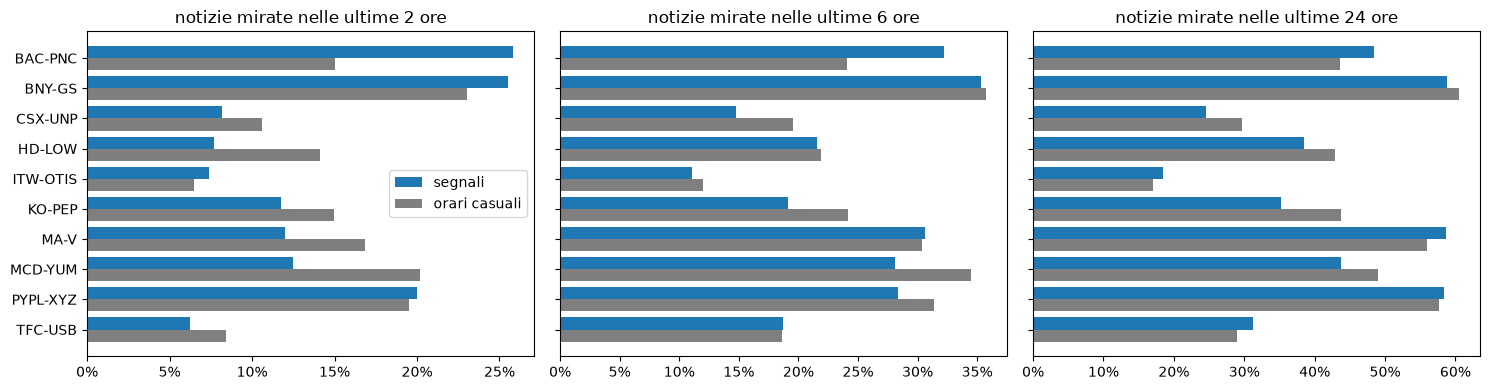

,pair,n_segnali,segnali_con_notizia,orari_casuali
3,MA-V,75,0.31,0.30
9,TFC-USB,64,0.19,0.19
15,BAC-PNC,62,0.32,0.24
21,CSX-UNP,61,0.15,0.20
27,PYPL-XYZ,60,0.28,0.31
33,BNY-GS,51,0.35,0.36
39,HD-LOW,65,0.22,0.22
45,ITW-OTIS,54,0.11,0.12
51,MCD-YUM,64,0.28,0.34
57,KO-PEP,68,0.19,0.24


In [5]:
def count_before(ts_sorted, when, hours):
    # quante notizie (di ts_sorted, ordinate) hanno ts nell'intervallo (when - hours, when]
    when = np.asarray(when, dtype="datetime64[ns]")
    lo = np.searchsorted(ts_sorted, when - np.timedelta64(int(hours * 3600), "s"), side="right")
    hi = np.searchsorted(ts_sorted, when, side="right")
    return hi - lo

rows = []
for _, r in pairs.iterrows():
    m = news[tick_cols[r.sym_A]] | news[tick_cols[r.sym_B]]
    arrs = {"qualsiasi": news.loc[m, "ts"].to_numpy(dtype="datetime64[ns]"), "mirate": news.loc[m & news.focused, "ts"].to_numpy(dtype="datetime64[ns]")}
    sig = signals[signals.pair == r.pair].t_signal.to_numpy(dtype="datetime64[ns]")
    d = load_pair(r.pair)
    days = np.array(sorted(set(d.ts[d.is_train].normalize())), dtype="datetime64[ns]")              # giorni di borsa del train di questa coppia
    sig_df = signals[signals.pair == r.pair]
    tod = (sig_df.t_signal - sig_df.t_signal.dt.normalize()).to_numpy()                             # ora del giorno di ogni segnale
    placebo = (np.random.default_rng(SEED).choice(days, size=(len(sig_df), N_PLACEBO_PER_SIGNAL)) + tod[:, None]).ravel()
    for h in WINDOWS_H:
        for name, arr in arrs.items():
            rows.append(dict(pair=r.pair, finestra_ore=h, notizie=name, n_segnali=len(sig), segnali_con_notizia=(count_before(arr, sig, h) > 0).mean(), orari_casuali=(count_before(arr, placebo, h) > 0).mean()))
cov = pd.DataFrame(rows)

# totale: quota dei segnali con notizia, e quota degli orari casuali pesata col numero di segnali di ogni coppia (stessa composizione per coppia)
tot = cov.assign(s=cov.segnali_con_notizia * cov.n_segnali, p=cov.orari_casuali * cov.n_segnali).groupby(["finestra_ore", "notizie"]).agg(s=("s", "sum"), p=("p", "sum"), n=("n_segnali", "sum"))
tot = pd.DataFrame({"segnali_con_notizia": tot.s / tot.n, "orari_casuali": tot.p / tot.n, "n_segnali": tot.n}).reset_index()
print("TOTALE (10 coppie):")
print(tot.assign(segnali_con_notizia=lambda x: x.segnali_con_notizia.map("{:.0%}".format), orari_casuali=lambda x: x.orari_casuali.map("{:.0%}".format)).to_string(index=False))

pv = cov[cov.notizie == "mirate"].pivot(index="pair", columns="finestra_ore", values="segnali_con_notizia")
pv_p = cov[cov.notizie == "mirate"].pivot(index="pair", columns="finestra_ore", values="orari_casuali")
fig, ax = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for a, h in zip(ax, WINDOWS_H):
    y = np.arange(len(pv))
    a.barh(y - 0.2, pv[h], 0.4, label="segnali", color="tab:blue"); a.barh(y + 0.2, pv_p[h], 0.4, label="orari casuali", color="tab:gray")
    a.set_yticks(y, pv.index); a.set_title(f"notizie mirate nelle ultime {h} ore"); a.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax[0].invert_yaxis(); ax[0].legend(); plt.tight_layout(); plt.show()
cov[(cov.notizie == "mirate") & (cov.finestra_ore == 6)][["pair", "n_segnali", "segnali_con_notizia", "orari_casuali"]].round(2)

**Lettura.** 
**Nota di metodo.** Il confronto è con giorni a caso **alla stessa ora del giorno** del segnale. Una prima versione lo faceva con orari di tutta la giornata: faceva sembrare i segnali poveri di notizie, ma era solo l'effetto dell'ora (il 43% dei segnali è nei minuti 15-30 dall'apertura, quando le ultime ore includono la notte).

| Finestra | Segnali con notizia (mirate) | Orari casuali (mirate) | Segnali (qualsiasi) | Orari casuali (qualsiasi) |
|---|---|---|---|---|
| 2 ore | 13% | 15% | 20% | 20% |
| 6 ore | 24% | 25% | 32% | 33% |
| 24 ore | 42% | 43% | 56% | 56% |

- **I segnali non hanno più notizie di orari casuali alla stessa ora.** Le differenze sono di uno o due punti, dentro l'errore: la presenza di una notizia **non è legata** ai movimenti anomali dello spread. Per coppia i valori sono simili (a 6 ore le differenze più grandi sono BAC-PNC 32% contro 24% in positivo, MCD-YUM 28% contro 34% e KO-PEP 19% contro 24% in negativo, con 51-75 segnali per coppia).
- **Quanti segnali hanno qualcosa da leggere**: con notizie mirate nelle ultime 2 ore circa 80 segnali su 624, a 6 ore circa 150, a 24 ore circa 260; con notizie di qualsiasi tipo nelle ultime 24 ore 347 (56%). Rispetto a MA-V da sola (circa 8 segnali con notizie mirate a 2 ore e 15 a 6 ore) sono circa 10 volte di più.
- **Per coppia, a 6 ore con notizie mirate**: da 11% (ITW-OTIS) a 35% (BNY-GS). Le coppie con meno notizie sono quelle dei titoli meno coperti (ITW, OTIS, CSX, PNC).

## 6. Le notizie c'entrano col risultato del trade?

L'ipotesi del progetto: i movimenti dello spread dovuti a un fatto vero non rientrano, quelli dovuti al rumore sì. Qui non classifichiamo le notizie (lo farà l'agente nel Passaggio 5): guardiamo solo se i trade **con** una notizia mirata nelle ultime ore vanno diversamente da quelli **senza**. È un controllo descrittivo: una notizia qualsiasi (anche un cambio di target price) non è per forza "un fatto", quindi una differenza piccola non dice nulla sul valore dell'agente. Guadagno lordo, senza costi.

In [6]:
rows = []
for h in WINDOWS_H:
    flags = []
    for _, s in signals.iterrows():
        r = pairs[pairs.pair == s.pair].iloc[0]
        m = (news[tick_cols[r.sym_A]] | news[tick_cols[r.sym_B]]) & news.focused
        flags.append(((news.ts <= s.t_signal) & (news.ts > s.t_signal - pd.Timedelta(hours=h)) & m).any())
    f = np.array(flags)
    for name, mask in [("con notizia mirata", f), ("senza notizia mirata", ~f)]:
        g = signals[mask]
        rows.append(dict(finestra_ore=h, gruppo=name, trade=len(g), lordo_medio_bps=g.gross_bps.mean(), errore_std=g.gross_bps.std() / np.sqrt(len(g)) if len(g) > 1 else np.nan,
                         quota_rientro=(g.exit_reason == "rientro").mean(), quota_in_positivo=(g.gross_bps > 0).mean()))
outcome = pd.DataFrame(rows)
outcome.style.format({"lordo_medio_bps": "{:.1f}", "errore_std": "{:.1f}", "quota_rientro": "{:.0%}", "quota_in_positivo": "{:.0%}"})

,finestra_ore,gruppo,trade,lordo_medio_bps,errore_std,quota_rientro,quota_in_positivo
0,2,con notizia mirata,84,18.0,9.8,46%,61%
1,2,senza notizia mirata,540,5.0,1.9,49%,59%
2,6,con notizia mirata,150,13.6,5.9,48%,60%
3,6,senza notizia mirata,474,4.6,2.0,48%,59%
4,24,con notizia mirata,261,11.5,4.0,53%,62%
5,24,senza notizia mirata,363,3.4,2.2,45%,58%


**Lettura.** 
Con una notizia mirata nelle ultime 6 ore i 150 trade guadagnano in media **13.6 bps lordi** (errore 5.9), contro **4.6** (errore 2.0) dei 474 senza notizia; con le finestre di 2 e 24 ore la differenza è simile (18.0 contro 5.0; 11.5 contro 3.4). La quota di trade che rientrano è invece uguale (46-53% contro 45-49%).

- **Va nella direzione opposta a quella dell'ipotesi del progetto** (una notizia dovrebbe impedire il rientro), ma la differenza è di 1.3-1.8 errori standard: non è significativa, e le notizie di cui parliamo sono per lo più rumore (cambi di target price, elenchi di titoli), non "fatti strutturali". Inoltre i giorni con notizie possono essere giorni più mossi, con più punti base per trade.
- **Non dice niente sul valore dell'agente**: per saperlo servono le notizie classificate (rumore o fatto) e il giudizio dell'agente. Qui conta il numero: tra 84 e 261 segnali hanno una notizia mirata, abbastanza per iniziare il Passaggio 5.

## 7. La tabella notizie-segnali (input del Passaggio 5)

Per ogni segnale si salvano tutte le notizie delle ultime 24 ore che citano uno dei due titoli della coppia, con quanti minuti prima del segnale sono uscite e se sono mirate. L'agente potrà usare solo le ultime 2 o 6 ore filtrando per `minutes_before`. Cartella ignorata da git: chi la vuole rilancia il notebook.

In [7]:
max_h = max(WINDOWS_H)
rows = []
for _, s in signals.iterrows():
    r = pairs[pairs.pair == s.pair].iloc[0]
    mA, mB = news[tick_cols[r.sym_A]], news[tick_cols[r.sym_B]]
    w = news[(mA | mB) & (news.ts <= s.t_signal) & (news.ts > s.t_signal - pd.Timedelta(hours=max_h))]
    for i, n in w.iterrows():
        rows.append(dict(signal_id=s.signal_id, pair=s.pair, t_signal=s.t_signal, direction=s.direction, leg_piu_mosso=s.leg_piu_mosso, news_id=n.id, news_ts=n.ts,
                         minutes_before=(s.t_signal - n.ts).total_seconds() / 60, headline=n.headline, summary=n.summary, source=n.source, symbols=n.symbols,
                         n_symbols=n.n_symbols, focused=n.focused, mentions_A=bool(mA[i]), mentions_B=bool(mB[i]), url=n.url))
link = pd.DataFrame(rows)
assert (link.news_ts <= link.t_signal).all(), "una notizia è successiva al segnale"
OUT_LINK.parent.mkdir(parents=True, exist_ok=True)
link.to_csv(OUT_LINK, index=False)
print(f"{len(link)} coppie (segnale, notizia) per {link.signal_id.nunique()} segnali su {len(signals)} (gli altri non hanno nessuna notizia nelle ultime {max_h} ore)")
print(f"salvato in {OUT_LINK}")
link.head()

1008 coppie (segnale, notizia) per 347 segnali su 624 (gli altri non hanno nessuna notizia nelle ultime 24 ore)
salvato in ../data/processed/news_for_signals_10pairs_train.csv


,signal_id,pair,t_signal,direction,leg_piu_mosso,news_id,news_ts,minutes_before,headline,summary,source,symbols,n_symbols,focused,mentions_A,mentions_B,url
0,0,MCD-YUM,2026-06-16 10:54:00,short MCD / long YUM,YUM,53200728,2026-06-15 11:29:34,1404.433333,The Hormuz Reopening Trade: These 20 Large-Cap...,Wall Street marched near records as the Strait...,benzinga,"ABT,ACN,BABA,CRM,GLD,MCD,NEM,PDD,PEP,SAP,UL",11,False,True,False,https://www.benzinga.com/markets/equities/26/0...
1,0,MCD-YUM,2026-06-16 10:54:00,short MCD / long YUM,YUM,53205499,2026-06-15 13:35:37,1278.383333,10 Consumer Discretionary Stocks Whale Activit...,,benzinga,"AMZN,CVNA,CWH,DASH,EXPE,MAR,MCD,TSLA,ULTA,VSXY",10,False,True,False,https://www.benzinga.com/insights/options/26/0...
2,0,MCD-YUM,2026-06-16 10:54:00,short MCD / long YUM,YUM,53219265,2026-06-16 08:02:49,171.183333,Yum! Brand Sells Pizza Hut Unit For $2.7B To L...,,benzinga,"YUM,YUMC",2,True,False,True,https://www.benzinga.com/news/26/06/53219265/y...
3,0,MCD-YUM,2026-06-16 10:54:00,short MCD / long YUM,YUM,53221686,2026-06-16 09:09:35,104.416667,Yum! Brands Is Selling One Of America's Most I...,Yum Brands sells Pizza Hut to LongRange Capita...,benzinga,"DASH,DPZ,PEP,YUM,YUMC",5,False,False,True,https://www.benzinga.com/m-a/26/06/53221686/yu...
4,1,KO-PEP,2026-06-16 11:04:00,short KO / long PEP,PEP,53200728,2026-06-15 11:29:34,1414.433333,The Hormuz Reopening Trade: These 20 Large-Cap...,Wall Street marched near records as the Strait...,benzinga,"ABT,ACN,BABA,CRM,GLD,MCD,NEM,PDD,PEP,SAP,UL",11,False,False,True,https://www.benzinga.com/markets/equities/26/0...


## 8. Esempi da leggere a mano

Per ogni coppia si prende il primo segnale con almeno una notizia mirata nelle ultime 6 ore, e si leggono i titoli come li vedrebbe l'agente. Serve a capire a occhio se le notizie c'entrano col movimento, ed è la base per classificare a mano 30-50 segnali (programma, Passaggio 5).

In [8]:
for p in pairs.pair:
    cand = link[(link.pair == p) & link.focused & (link.minutes_before <= 6 * 60)]
    if cand.empty:
        print(f"\n=== {p}: nessun segnale con notizie mirate nelle ultime 6 ore ===")
        continue
    sid = cand.sort_values("t_signal").iloc[0].signal_id
    s = signals[signals.signal_id == sid].iloc[0]
    print(f"\n=== {p}, segnale {sid}: {s.t_signal}, {s.direction}, si è mosso di più {s.leg_piu_mosso}, risultato lordo {s.gross_bps:.0f} bps ===")
    for _, n in cand[cand.signal_id == sid].sort_values("minutes_before").head(4).iterrows():
        print(f"  -{n.minutes_before:5.0f} min [{n.symbols}] {n.headline[:105]}")


=== MA-V, segnale 28: 2026-06-17 15:26:00, long MA / short V, si è mosso di più MA, risultato lordo -12 bps ===
  -  266 min [MSFT,SPG,V] Illinois Rep. Jonathan Jackson Sold Up to $50K Worth of Microsoft Stock

=== TFC-USB, segnale 98: 2026-07-01 09:47:00, long TFC / short USB, si è mosso di più TFC, risultato lordo 31 bps ===
  -  189 min [TFC] Raymond James Downgrades Truist Financial to Market Perform

=== BAC-PNC, segnale 31: 2026-06-18 14:14:00, long BAC / short PNC, si è mosso di più BAC, risultato lordo 22 bps ===
  -  171 min [BAC] Bank Of America's July 2022 Cease, Desist Order Terminated By U.S. Office Of The Comptroller Of The Curre

=== CSX-UNP, segnale 22: 2026-06-17 12:56:00, short CSX / long UNP, si è mosso di più UNP, risultato lordo 35 bps ===
  -  296 min [CSX] B of A Securities Maintains Buy on CSX, Raises Price Target to $53

=== PYPL-XYZ, segnale 94: 2026-06-30 10:49:00, long PYPL / short XYZ, si è mosso di più PYPL, risultato lordo 41 bps ===
  -  135 min [META,P

## 9. Conclusioni e cose aperte

I numeri sono quelli dell'esecuzione sul train (notizie dal 1 giugno al 16 settembre 2026, scaricate il 6 novembre 2026) e sui 624 segnali di `segnali_coppie.ipynb`. Se si scaricano di nuovo le notizie o si cambiano i segnali, vanno riaggiornati.

### Cosa abbiamo trovato
1. **1250 notizie sui 20 titoli**, una sola fonte (Benzinga), 67% mirate; copertura molto disomogenea tra i titoli (da 9 notizie per OTIS a 222 per GS). **ITW-OTIS ha praticamente zero notizie.**
2. **347 segnali su 624 (56%) hanno almeno una notizia nelle ultime 24 ore** (1008 coppie segnale-notizia in `data/processed/news_for_signals_10pairs_train.csv`). Con notizie mirate: 84 segnali nelle ultime 2 ore, 150 nelle ultime 6, 261 nelle ultime 24.
3. **I segnali non coincidono con le notizie**: stessa quota degli orari casuali alla stessa ora del giorno (per esempio 24% contro 25% a 6 ore con notizie mirate). Non si vede una relazione tra una notizia e un movimento anomalo dello spread.
4. **Esito dei trade**: quelli con una notizia mirata guadagnano di più in media (13.6 contro 4.6 bps a 6 ore) ma la differenza non è significativa, e le notizie sono per lo più rumore.
5. **Esempi letti a mano (parte 8)**: soprattutto cambi di target price e giudizi degli analisti su un titolo solo, qualche notizia con molti ticker, e rari fatti veri (per esempio la vendita di Pizza Hut da parte di Yum! il 16 giugno, 171 minuti prima di un segnale su MCD-YUM chiuso a -25 bps lordi). Un singolo esempio non prova niente.

### Cosa significa per l'agente (Passaggio 5)
- **Rispetto a MA-V da sola il Passaggio 5 diventa fattibile**: con la finestra di 6 ore e notizie mirate l'agente ha qualcosa da leggere per circa 150 segnali (contro circa 15 di MA-V), con 24 ore per circa 260-350. Le chiamate all'LLM sarebbero poche centinaia.
- **Il confronto tra le tre versioni** (A senza agente, B che blocca, C che decide) si farebbe su 80-260 segnali con notizia: meglio che su 15, ma il risultato resterà incerto (errori standard di 6-10 bps) e le notizie sono per lo più rumore, quindi l'agente avrà poche occasioni di bloccare un fatto vero.
- **Una seconda fonte** servirebbe soprattutto per le coppie con pochissime notizie (ITW-OTIS e, in misura minore, quelle con titoli poco coperti: CSX, PNC, TFC, USB): vedi `Programma.md`.

### Cose aperte
1. **Orario vero di pubblicazione**: controllo a mano di 10 notizie (tabella della parte 4), da fare dal gruppo.
2. **Seconda fonte di notizie** e **raggruppamento dei duplicati**.
3. **Finestra di ricerca** (2, 6 o 24 ore) e uso delle notizie con molti ticker: da confrontare nel Passaggio 5; si può partire da 6 ore.
4. **Classificazione a mano** di 30-50 segnali con notizia, per misurare l'accordo con l'agente (programma, Passaggio 5).
5. **Segnali ancora provvisori**: lo stato del Passaggio 4 (orari di ingresso, barre riempite, costi) può cambiare i segnali e quindi anche questa tabella.

### Limiti da dichiarare nel report
- Una sola fonte e copertura incompleta ("nessuna notizia" non vuol dire "non è successo niente").
- Notizie associate ai ticker da Benzinga: una notizia taggata con un titolo non è per forza su quell'azienda.
- Segnali non indipendenti e orari non ancora verificati a mano.
- Solo titolo e sommario, non il testo completo.